In [1]:
import os
from dotenv import load_dotenv

load_dotenv()

groq_api_key = os.getenv("GROQ_API_KEY")
tavily_api_key = os.getenv("TAVILY_API_KEY")
pinecone_api_key = os.getenv("PINECONE_API_KEY")

print("GROQ_API_KEY configured:", bool(groq_api_key))
print("TAVILY_API_KEY configured:", bool(tavily_api_key))
print("PINECONE_API_KEY configured:", bool(pinecone_api_key))

GROQ_API_KEY configured: True
TAVILY_API_KEY configured: True
PINECONE_API_KEY configured: True


In [2]:
from langchain_groq import ChatGroq

# Replace this model if your Groq dashboard shows a different available model.
llm = ChatGroq(
    model="openai/gpt-oss-20b",
    temperature=0,
)

WebBased Loader

In [3]:
# from langchain_community.document_loaders import WebBaseLoader

# SOURCE_URL = "https://docs.langchain.com/oss/python/langgraph/agentic-rag"

# loader = WebBaseLoader(
#     web_paths=(SOURCE_URL,),
#     requests_kwargs={
#         "headers": {
#             "User-Agent": "Mozilla/5.0 Agentic-RAG-Industry-Demo"
#         }
#     },
# )

# raw_docs_web = loader.load()

# print("Loaded documents:", len(raw_docs_web))
# print("Source:", raw_docs_web[0].metadata.get("source"))
# print("\nPreview:\n")
# print(raw_docs_web[0].page_content[:1500])

In [4]:
from typing import List, TypedDict
import time

from langchain_community.document_loaders import PyPDFLoader
from langchain_community.vectorstores import FAISS
from langchain_groq import ChatGroq
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_core.documents import Document
from langchain_core.prompts import ChatPromptTemplate

from langchain_huggingface import HuggingFaceEmbeddings

from langgraph.graph import StateGraph, START, END

C:\Users\ce\AppData\Local\Temp\ipykernel_27828\1632695223.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import PyPDFLoader
c:\Users\ce\AppData\Local\Programs\Python\Python310\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
raw_docs = (
    PyPDFLoader(r"P:\Advanced-Jijnasa-AI\covid-19.pdf").load()
    # + PyPDFLoader(r"P:\ADVANCED_RAG\Self_RAG\documents\Company_Profile.pdf").load()
    # + PyPDFLoader(r"P:\ADVANCED_RAG\Self_RAG\documents\Product_and_Pricing.pdf").load()
)


# raw_docs = loader.load()

print("Loaded documents:", len(raw_docs))
print("Source:", raw_docs[0].metadata.get("source"))
print("\nPreview:\n")
print(raw_docs[0].page_content[:1500])

Ignoring wrong pointing object 18 0 (offset 0)
Ignoring wrong pointing object 20 0 (offset 0)
Ignoring wrong pointing object 22 0 (offset 0)
Ignoring wrong pointing object 24 0 (offset 0)
Ignoring wrong pointing object 26 0 (offset 0)
Ignoring wrong pointing object 55 0 (offset 0)
Ignoring wrong pointing object 64 0 (offset 0)
Ignoring wrong pointing object 137 0 (offset 0)
Ignoring wrong pointing object 177 0 (offset 0)
Ignoring wrong pointing object 179 0 (offset 0)
Ignoring wrong pointing object 181 0 (offset 0)
Ignoring wrong pointing object 202 0 (offset 0)
Ignoring wrong pointing object 287 0 (offset 0)
Ignoring wrong pointing object 289 0 (offset 0)
Ignoring wrong pointing object 311 0 (offset 0)
Ignoring wrong pointing object 313 0 (offset 0)
Ignoring wrong pointing object 315 0 (offset 0)
Ignoring wrong pointing object 391 0 (offset 0)
Ignoring wrong pointing object 412 0 (offset 0)


Loaded documents: 18
Source: P:\Advanced-Jijnasa-AI\covid-19.pdf

Preview:

The picture can't be 
displayed.
The picture can't 
be displayed.
What is COVID-19
•COVID-19 is the infectious disease caused by the most recently 
discovered coronavirus1
•This new virus and disease were unknown before the outbreak 
began in Wuhan, China, in December 2019
•COVID-19 is now a pandemic affecting many countries globally
1https://www.who.int/emergencies/diseases/novel-coronavirus-2019/question-and-answers-hub/q-a-detail/q-a-coronaviruses


In [6]:
len(raw_docs)

18

In [7]:
raw_docs

[Document(metadata={'producer': 'macOS Version 10.15.5 (Build 19F101) Quartz PDFContext', 'creator': 'PyPDF', 'creationdate': "D:20200623103112Z00'00'", 'moddate': "D:20200623103112Z00'00'", 'source': 'P:\\Advanced-Jijnasa-AI\\covid-19.pdf', 'total_pages': 18, 'page': 0, 'page_label': '1'}, page_content="The picture can't be \ndisplayed.\nThe picture can't \nbe displayed.\nWhat is COVID-19\n•COVID-19 is the infectious disease caused by the most recently \ndiscovered coronavirus1\n•This new virus and disease were unknown before the outbreak \nbegan in Wuhan, China, in December 2019\n•COVID-19 is now a pandemic affecting many countries globally\n1https://www.who.int/emergencies/diseases/novel-coronavirus-2019/question-and-answers-hub/q-a-detail/q-a-coronaviruses"),
 Document(metadata={'producer': 'macOS Version 10.15.5 (Build 19F101) Quartz PDFContext', 'creator': 'PyPDF', 'creationdate': "D:20200623103112Z00'00'", 'moddate': "D:20200623103112Z00'00'", 'source': 'P:\\Advanced-Jijnasa-AI\

In [8]:
import re
import unicodedata


def clean_text(text: str) -> str:

    if not isinstance(text, str):
        text = str(text)

    # --------------------------------------------------
    # 1. Fix NULL-byte separated ASCII text
    # Example:
    # \x00D\x00o\x00w\x00n\x00l\x00o\x00a\x00d
    # becomes:
    # Download
    # --------------------------------------------------
    if "\x00" in text:

        # If NULL bytes are separating ASCII characters,
        # simply remove them.
        text = text.replace("\x00", "")

    # --------------------------------------------------
    # 2. Unicode normalization
    # --------------------------------------------------
    text = unicodedata.normalize("NFKC", text)

    # --------------------------------------------------
    # 3. Remove remaining control characters
    # --------------------------------------------------
    text = "".join(
        ch
        for ch in text
        if ch in ("\n", "\t")
        or not unicodedata.category(ch).startswith("C")
    )

    # --------------------------------------------------
    # 4. Normalize spaces
    # --------------------------------------------------
    text = re.sub(r"[ \t]+", " ", text)

    # --------------------------------------------------
    # 5. Normalize newlines
    # --------------------------------------------------
    text = re.sub(r"\n{3,}", "\n\n", text)

    return text.strip()

In [9]:
bad_text = """Preface
\x00D\x00o\x00w\x00n\x00l\x00o\x00a\x00d\x00 \x00f\x00r\x00o\x00m\x00 \x00f\x00i\x00n\x00e\x00l\x00y\x00b\x00o\x00o\x00k\x00 \x00w\x00w\x00w\x00.\x00f\x00i\x00n\x00e\x00l\x00y\x00b\x00o\x00o\x00k\x00.\x00c\x00o\x00m"""

cleaned = clean_text(bad_text)

print(cleaned)

Preface
Download from finelybook www.finelybook.com


In [10]:
from langchain_core.documents import Document

clean_raw_docs = []

for doc in raw_docs:

    cleaned_text = clean_text(doc.page_content)

    clean_raw_docs.append(
        Document(
            page_content=cleaned_text,
            metadata=doc.metadata.copy()
        )
    )

print("Original documents:", len(raw_docs))
print("Clean documents:", len(clean_raw_docs))

Original documents: 18
Clean documents: 18


In [11]:
from langchain_text_splitters import RecursiveCharacterTextSplitter

splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=200,
    add_start_index=True,
)

chunks = splitter.split_documents(clean_raw_docs)

print("Total chunks:", len(chunks))
print("\nFirst chunk preview:\n")
print(chunks[0].page_content[:900])

Total chunks: 18

First chunk preview:

The picture can't be 
displayed.
The picture can't 
be displayed.
What is COVID-19
•COVID-19 is the infectious disease caused by the most recently 
discovered coronavirus1
•This new virus and disease were unknown before the outbreak 
began in Wuhan, China, in December 2019
•COVID-19 is now a pandemic affecting many countries globally
1https://www.who.int/emergencies/diseases/novel-coronavirus-2019/question-and-answers-hub/q-a-detail/q-a-coronaviruses


In [12]:
from langchain_huggingface import HuggingFaceEmbeddings

embeddings = HuggingFaceEmbeddings(
    model_name="sentence-transformers/all-MiniLM-L6-v2",
    encode_kwargs={"normalize_embeddings": True},
)

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 3301.34it/s]


In [13]:
sample_vector = embeddings.embed_query("What is Covid 19?")
print("Embedding dimensions:", len(sample_vector))

Embedding dimensions: 384


In [14]:
sample_vector[:10]

[-0.048650771379470825,
 0.048278193920850754,
 -0.07587932050228119,
 -0.017526857554912567,
 0.06013037636876106,
 0.055137742310762405,
 -0.002503875410184264,
 0.04450041055679321,
 -0.004176274873316288,
 0.024440770968794823]

In [15]:
from langchain_chroma import Chroma

PERSIST_DIR = "./advanced_multimodal_hybrid_rag_db"

vectorstore = Chroma.from_documents(
    documents=chunks,
    embedding=embeddings,
    persist_directory=PERSIST_DIR,
    collection_name="amhr_demo",
)

print("Vectorstore created and persisted at:", PERSIST_DIR)

# Sanity check
query = "What is Agentic RAG?"
results = vectorstore.similarity_search(query, k=3)

print(f"\nTop {len(results)} results for query: '{query}'\n")
for i, doc in enumerate(results, 1):
    print(f"--- Result {i} ---")
    print("Page:", doc.metadata.get("page"))
    print(doc.page_content[:300])
    print()

Vectorstore created and persisted at: ./advanced_multimodal_hybrid_rag_db

Top 3 results for query: 'What is Agentic RAG?'

--- Result 1 ---
Page: 5
The picture can't be 
displayed.
The picture can't 
be displayed.
Transmission
Transmission: 2/2
Active viral replication occurs in the 
upper respiratory tract and lungs. Early 
studies indicate that the virus replicates 
in the gastrointestinal tract but faecal-
oral transmission has not been conf

--- Result 2 ---
Page: 5
The picture can't be 
displayed.
The picture can't 
be displayed.
Transmission
Transmission: 2/2
Active viral replication occurs in the 
upper respiratory tract and lungs. Early 
studies indicate that the virus replicates 
in the gastrointestinal tract but faecal-
oral transmission has not been conf

--- Result 3 ---
Page: 12
The picture can't be 
displayed.
The picture can't 
be displayed.
Treatment
Currently, there are no antiviral drugs licensed for treating COVID-19. 
Research is ongoing to determine if existing dr

In [16]:
from langchain_chroma import Chroma

PERSIST_DIR = "./advanced_multimodal_hybrid_rag_db"
COLLECTION_NAME = "amhr_demo"

vectorstore = Chroma(
    collection_name=COLLECTION_NAME,
    embedding_function=embeddings,
    persist_directory=PERSIST_DIR,
)

print("Existing Chroma collection loaded:", COLLECTION_NAME)
print("Stored chunks:", vectorstore._collection.count())

Existing Chroma collection loaded: amhr_demo
Stored chunks: 36


In [17]:
retriever = vectorstore.as_retriever(search_type="similarity", search_kwargs={"k": 4})

In [18]:
# class State(TypedDict):
#     question: str
#     docs: List[Document]
#     answer: str

In [19]:
# def retrieve(state):
#     q = state["question"]
#     return {"docs": retriever.invoke(q)}

In [20]:
# from langchain_core.prompts import ChatPromptTemplate
# from langchain_core.output_parsers import StrOutputParser


# prompt = ChatPromptTemplate.from_template(
#     """Answer the question based only on the following context.
# Respond in plain text only — do not use markdown formatting such as asterisks, bold, italics, bullet symbols, or headers. Use plain sentences or simple numbered lines instead.

# {context}

# Question: {question}
# """
# )


# def generate(state):
#     # Convert retrieved LangChain Documents into plain text
#     context = "\n\n".join(
#         doc.page_content
#         for doc in state["docs"]
#     )

#     # Prompt → LLM → plain string
#     answer = (
#         prompt
#         | llm
#         | StrOutputParser()
#     ).invoke(
#         {
#             "question": state["question"],
#             "context": context,
#         }
#     )

#     return {
#         "answer": answer
#     }

In [21]:
# g = StateGraph(State)
# g.add_node("retrieve", retrieve)
# g.add_node("generate", generate)
# g.add_edge(START, "retrieve")
# g.add_edge("retrieve", "generate")
# g.add_edge("generate", END)
# app = g.compile()

# app

In [22]:
# # 5) Run
# res = app.invoke({"question": "What is Super-spreading events", "docs": [], "answer": ""})
# print(res["answer"])

In [23]:
test_question = "What is Covid 19 and what are its symptoms?"

kb_docs = retriever.invoke(test_question)

for i, doc in enumerate(kb_docs, 1):
    print(f"\n--- KB RESULT {i} ---")
    print("Source:", doc.metadata.get("source"))
    print("Page:", doc.metadata.get("page"))
    print(doc.page_content[:700])


--- KB RESULT 1 ---
Source: P:\Advanced-Jijnasa-AI\covid-19.pdf
Page: 4
The picture can't be 
displayed.
The picture can't 
be displayed.
Transmission 
Transmission: 1/2
COVID-19 is spread primarily from person to person through small 
droplets from the nose or mouth, expelled when a person with COVID-
19 coughs or sneezes. People can catch COVID-19 if they breathe in 
these droplets, or by touching objects or surfaces where the droplets 
have landed, then their face. 
The time between infection and first symptoms (incubation period) 
ranges from 1 to 14 days, with an average of 5 to 6 days. More than 
97% of people experience symptoms within 14 days. 
Source:ID card

--- KB RESULT 2 ---
Source: P:\Advanced-Jijnasa-AI\covid-19.pdf
Page: 4
The picture can't be 
displayed.
The picture can't 
be displayed.
Transmission 
Transmission: 1/2
COVID-19 is spread primarily from person to person through small 
droplets from the nose or mouth, expelled when a person with COVID-
19 coughs or sneez

In [24]:
print(llm.invoke("Explain Agentic RAG in one sentence.").content)

Agentic RAG is a retrieval‑augmented generation approach in which an autonomous agent actively selects, prioritizes, and incorporates relevant external documents to inform and improve its generated responses.


In [25]:
from langchain_tavily import TavilySearch

web_search = TavilySearch(
    max_results=5,
    topic="general",
    include_answer=True,
    include_raw_content=False,
)

print("Tavily search tool ready.")

Tavily search tool ready.


In [26]:
from langchain_community.tools import ArxivQueryRun
from langchain_community.utilities import ArxivAPIWrapper


# --- Tool 2: arXiv research papers ---
arxiv_tool = ArxivQueryRun(
    api_wrapper=ArxivAPIWrapper(
        top_k_results=3,
        doc_content_chars_max=2000,
    )
)

print("arXiv search tool ready.")

arXiv search tool ready.


In [27]:
# --- Bind both tools to the LLM (tool calling) ---
external_tools = [web_search, arxiv_tool]
tools_by_name = {t.name: t for t in external_tools}
tool_llm = llm.bind_tools(external_tools)

print("Tools ready:", list(tools_by_name.keys()))

Tools ready: ['tavily_search', 'arxiv']


In [69]:
from typing import List, Literal, Optional
from typing_extensions import TypedDict
from pydantic import BaseModel, Field
from langchain_core.documents import Document


class RouteDecision(BaseModel):
    route: Literal["kb", "external", "direct"] = Field(
        description="kb for COVID-19 document questions; external for arXiv papers/IDs, research and current news; direct for greetings/small talk."
    )


class EvidenceGrade(BaseModel):
    grade: Literal["good", "weak"] = Field(
        description="good means evidence can answer the question; weak means not enough evidence."
    )


class AgentState(TypedDict):
    question: str
    current_query: str
    kb_docs: List[Document]
    external_results: str      # combined output from Tavily and/or arXiv
    tools_used: List[str]      # which external tools were called
    kb_grade: str
    external_grade: str
    answer: str
    source_used: str
    retry_count: int

In [70]:
import re

router_llm = llm.with_structured_output(RouteDecision, method="json_mode")

# Matches arXiv IDs such as 1706.03762, arXiv:1706.03762, 2005.11401v2
ARXIV_ID_RE = re.compile(r"\b(?:arxiv:)?(\d{4}\.\d{4,5})(?:v\d+)?\b", re.I)

def route_question(state: AgentState):
    question = state["question"]

    # Rule-based shortcut: an arXiv ID always goes to the external tools.
    if ARXIV_ID_RE.search(question):
        print("[Router] external (arXiv ID detected)")
        return {"current_query": question, "source_used": "external"}

    decision = router_llm.invoke(f'''
You are a router for an Agentic RAG assistant.
The private knowledge base contains a document about COVID-19.

Choose exactly one route:

"kb" -> the question is about COVID-19 / coronavirus / SARS-CoV-2:
  symptoms, transmission, prevention, vaccines, treatment, the pandemic,
  statistics, public health measures, or anything the COVID-19 document may answer.

"external" -> the question needs outside information:
  - arXiv papers, arXiv IDs, research papers, preprints, scientific/academic topics
  - current news, latest updates, recent events
  - any factual question that is clearly NOT about the COVID-19 document
  - questions asking "what is <paper id / paper title / tool / technology>"

"direct" -> ONLY greetings, thanks, or small talk (e.g. "hello", "thank you").
  Never use "direct" for a factual question.

Question:
{question}

Return your response as valid JSON.
Example:
{{"route": "kb"}}
''')

    print("[Router]", decision.route)

    return {
        "current_query": question,
        "source_used": decision.route,
    }


def route_after_router(state: AgentState) -> Literal["retrieve_kb", "search_external", "direct_answer"]:
    route = state["source_used"]
    if route == "kb":
        return "retrieve_kb"
    if route == "external":
        return "search_external"
    return "direct_answer"

In [71]:
def retrieve_kb(state: AgentState):
    query = state["current_query"]
    docs = retriever.invoke(query)

    print(f"[KB Retriever] Query: {query}")
    print(f"[KB Retriever] Retrieved: {len(docs)} chunks")

    return {"kb_docs": docs}

In [72]:
kb_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_kb_evidence(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"Source: {doc.metadata.get('source')} (page {doc.metadata.get('page')})\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    grade = kb_grader_llm.invoke(f'''
You are an evidence grader.

Question:
{question}

Private KB evidence:
{context}

Can this private KB evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade": "good"}}
''')

    print("[KB Grader]", grade.grade)

    return {"kb_grade": grade.grade}


def decide_after_kb_grade(state: AgentState) -> Literal["generate_from_kb", "search_web"]:
    if state["kb_grade"] == "good":
        return "generate_from_kb"
    return "search_web"

In [73]:
import re

def format_tavily(result) -> str:
    # Tavily can return dict/list structures depending on package version.
    if isinstance(result, dict):
        answer = result.get("answer", "")
        results = result.get("results", [])
        lines = []
        if answer:
            lines.append(f"Tavily answer: {answer}")
        for item in results:
            lines.append(
                f"Title: {item.get('title', '')}\n"
                f"URL: {item.get('url', '')}\n"
                f"Content: {item.get('content', '')}"
            )
        return "\n\n".join(lines) if lines else str(result)
    return str(result)


TOOL_LABELS = {
    "tavily_search": "Tavily Web Search",
    "arxiv": "arXiv Research Papers",
}

# Guardrails: words that tell us which tool the question needs.
PAPER_HINT_RE = re.compile(r"\b(papers?|research|arxiv|studies|study|preprints?|literature|journals?)\b", re.I)
WEB_HINT_RE = re.compile(r"\b(news|current|currently|latest|today|updates?)\b", re.I)


def clean_arxiv_query(q: str) -> str:
    # arXiv search is keyword based: drop the word "arxiv" and years the LLM likes to add.
    q = re.sub(r"\b(arxiv|20\d\d)\b", "", q, flags=re.I)
    return re.sub(r"\s+", " ", q).strip()


def is_empty_result(text: str) -> bool:
    t = text.strip()
    return len(t) < 100 or t.lower().startswith(("no good", "tool error", "error"))


def run_tool(name: str, args: dict) -> str:
    print(f"[External Tools] Calling: {name} | args: {args}")
    try:
        result = tools_by_name[name].invoke(args)
        return format_tavily(result) if name == "tavily_search" else str(result)
    except Exception as e:
        return f"Tool error: {e}"


def search_external(state: AgentState):
    query = state["current_query"]
    original = state["question"]

    ai_msg = tool_llm.invoke(f'''
You are a research assistant with two tools.

- "arxiv": scientific / academic research papers. The query MUST be a short keyword phrase
  (3-6 words). Do NOT put the word "arxiv" or a year in the query.
  If the question contains an arXiv ID (like 1706.03762), pass ONLY that ID as the query.
- "tavily_search": news, current events, statistics, definitions and general web information.

If the question asks for BOTH research papers AND news/current information, call BOTH tools.
The private knowledge base was not enough, so you MUST call at least one tool.

Question:
{query}
''')

    # 1) tools chosen by the LLM
    planned = {}
    for call in ai_msg.tool_calls:
        if call["name"] in tools_by_name and call["name"] not in planned:
            planned[call["name"]] = dict(call["args"])

    # 2) guardrails on top of the LLM's choice
    ids = ARXIV_ID_RE.findall(original)
    if ids:
        planned["arxiv"] = {"query": ids[0]}                      # clean ID only
    elif "arxiv" in planned:
        planned["arxiv"]["query"] = clean_arxiv_query(planned["arxiv"].get("query", query))
    elif PAPER_HINT_RE.search(original):
        planned["arxiv"] = {"query": clean_arxiv_query(query)}

    if WEB_HINT_RE.search(original) and "tavily_search" not in planned:
        planned["tavily_search"] = {"query": query}

    if not planned:
        print("[External Tools] No tool chosen -> using both tools")
        planned = {"tavily_search": {"query": query}, "arxiv": {"query": clean_arxiv_query(query)}}

    # 3) run the tools
    outputs, used = {}, []
    for name, args in planned.items():
        outputs[name] = run_tool(name, args)
        used.append(name)

    # 4) if arXiv found nothing and Tavily was not used, fall back to Tavily
    if "arxiv" in outputs and is_empty_result(outputs["arxiv"]) and "tavily_search" not in outputs:
        print("[External Tools] arXiv returned nothing useful ->", outputs["arxiv"][:100])
        outputs["tavily_search"] = run_tool("tavily_search", {"query": query})
        used.append("tavily_search")

    # 5) keep only useful outputs
    sections = []
    for name, text in outputs.items():
        if is_empty_result(text):
            print(f"[External Tools] {name} returned little/nothing:", text[:100])
            continue
        sections.append(f"=== Source: {TOOL_LABELS.get(name, name)} ===\n{text}")

    external_text = "\n\n".join(sections)

    print("[External Tools] Tools used:", used)
    print("[External Tools] Result characters:", len(external_text))

    return {
        "external_results": external_text,
        "tools_used": used,
        "source_used": "external",
    }

In [33]:
# def search_web(state: AgentState):
#     query = state["current_query"]

#     print(f"[Tavily Search] Query: {query}")

#     result = web_search.invoke({"query": query})

#     # Tavily can return dict/list structures depending on package version.
#     # Convert it into readable text for grading and generation.
#     if isinstance(result, dict):
#         answer = result.get("answer", "")
#         results = result.get("results", [])
#         lines = []
#         if answer:
#             lines.append(f"Tavily answer: {answer}")

#         for item in results:
#             title = item.get("title", "")
#             url = item.get("url", "")
#             content = item.get("content", "")
#             lines.append(f"Title: {title}\nURL: {url}\nContent: {content}")

#         web_text = "\n\n".join(lines) if lines else str(result)
#     else:
#         web_text = str(result)

#     print("[Tavily Search] Result characters:", len(web_text))

#     return {
#         "web_results": web_text,
#         "source_used": "web",
#     }

In [34]:
# web_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

# def grade_web_evidence(state: AgentState):
#     question = state["question"]
#     web_results = state["web_results"]

#     grade = web_grader_llm.invoke(f'''
# You are an evidence grader.

# Question:
# {question}

# Web search evidence:
# {web_results}

# Can this web evidence answer the question?
# Return "good" if it can answer.
# Return "weak" if it cannot answer or is incomplete.

# Return your response as valid JSON.
# Example:
# {{"grade": "good"}}
# ''')

#     print("[Web Grader]", grade.grade)

#     return {"web_grade": grade.grade}


# MAX_RETRIES = 1

# def decide_after_web_grade(state: AgentState) -> Literal["generate_from_web", "rewrite_query", "answer_insufficient"]:
#     if state["web_grade"] == "good":
#         return "generate_from_web"

#     if state["retry_count"] < MAX_RETRIES:
#         return "rewrite_query"

#     return "answer_insufficient"

In [74]:
external_grader_llm = llm.with_structured_output(EvidenceGrade, method="json_mode")

def grade_external_evidence(state: AgentState):
    question = state["question"]
    external_results = state["external_results"]

    grade = external_grader_llm.invoke(f'''
You are an evidence grader.

Question:
{question}

External evidence (web search and/or arXiv papers):
{external_results}

Can this external evidence answer the question?
Return "good" if it can answer.
Return "weak" if it cannot answer or is incomplete.

Return your response as valid JSON.
Example:
{{"grade": "good"}}
''')

    print("[External Grader]", grade.grade)

    return {"external_grade": grade.grade}


MAX_RETRIES = 1

def decide_after_external_grade(state: AgentState) -> Literal["generate_from_external", "rewrite_query", "answer_insufficient"]:
    if state["external_grade"] == "good":
        return "generate_from_external"

    if state["retry_count"] < MAX_RETRIES:
        return "rewrite_query"

    return "answer_insufficient"

In [75]:
def rewrite_query(state: AgentState):
    question = state["question"]
    retry_count = state["retry_count"] + 1

    rewritten = llm.invoke(f'''
Rewrite the question for better retrieval and web search.

Rules:
- Preserve original intent.
- Make it specific and search-friendly.
- Do not answer.
- Return only the rewritten query.

Original question:
{question}
''').content.strip()

    print("[Rewriter]", rewritten)

    return {
        "current_query": rewritten,
        "retry_count": retry_count,
    }

In [76]:
def generate_from_kb(state: AgentState):
    question = state["question"]

    context = "\n\n".join(
        f"[KB Source: {doc.metadata.get('source')} | Page: {doc.metadata.get('page')}]\n{doc.page_content}"
        for doc in state["kb_docs"]
    )

    answer = llm.invoke(f'''
You are a helpful instructor.

Answer using ONLY the private KB context.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention that the answer is based on the private KB.
- Include source type: Private KB.

Question:
{question}

Private KB context:
{context}
''').content

    return {
        "answer": answer,
        "source_used": "private_kb",
    }

In [38]:
# def generate_from_web(state: AgentState):
#     question = state["question"]
#     web_context = state["web_results"]

#     answer = llm.invoke(f'''
# You are a helpful instructor.

# The private KB was insufficient, so web search was used.

# Answer using ONLY the web search context.

# Rules:
# - Beginner-friendly explanation.
# - Do not invent unsupported details.
# - Mention that the answer is based on Tavily web search.
# - Include source type: Web Search.
# - If URLs are present in context, include the most useful URLs.

# Question:
# {question}

# Web search context:
# {web_context}
# ''').content

#     return {
#         "answer": answer,
#         "source_used": "web_search",
#     }

In [77]:
def generate_from_external(state: AgentState):
    question = state["question"]
    external_context = state["external_results"]
    tools_used = ", ".join(state["tools_used"]) or "none"

    answer = llm.invoke(f'''
You are a helpful instructor.

The private KB was insufficient, so external tools were used: {tools_used}.

Answer using ONLY the external context below.

Rules:
- Beginner-friendly explanation.
- Do not invent unsupported details.
- Mention which sources the answer is based on (Tavily web search and/or arXiv papers).
- Include source type: Web Search and/or arXiv.
- If URLs are present, include the most useful URLs.
- For arXiv papers, mention the paper titles and authors when available.

Question:
{question}

External context:
{external_context}
''').content

    return {
        "answer": answer,
        "source_used": "external_tools",
    }

In [78]:
def direct_answer(state: AgentState):
    question = state["question"]

    answer = llm.invoke(f'''
Respond briefly and naturally.

Message:
{question}
''').content

    return {
        "answer": answer,
        "source_used": "direct",
    }

In [79]:
def answer_insufficient(state: AgentState):
    answer = (
        "I could not find enough reliable evidence in the private knowledge base "
        "or the external tools (web search / arXiv) to answer this confidently. "
        "Please provide more specific documents or rephrase the question."
    )

    return {
        "answer": answer,
        "source_used": "insufficient_evidence",
    }

In [80]:
from langgraph.graph import StateGraph, START, END

workflow = StateGraph(AgentState)

workflow.add_node("route_question", route_question)
workflow.add_node("retrieve_kb", retrieve_kb)
workflow.add_node("grade_kb_evidence", grade_kb_evidence)
workflow.add_node("search_external", search_external)
workflow.add_node("grade_external_evidence", grade_external_evidence)
workflow.add_node("rewrite_query", rewrite_query)
workflow.add_node("generate_from_kb", generate_from_kb)
workflow.add_node("generate_from_external", generate_from_external)
workflow.add_node("direct_answer", direct_answer)
workflow.add_node("answer_insufficient", answer_insufficient)

workflow.add_edge(START, "route_question")

workflow.add_conditional_edges(
    "route_question",
    route_after_router,
    {
        "retrieve_kb": "retrieve_kb",
        "search_external": "search_external",
        "direct_answer": "direct_answer",
    },
)

workflow.add_edge("retrieve_kb", "grade_kb_evidence")

workflow.add_conditional_edges(
    "grade_kb_evidence",
    decide_after_kb_grade,
    {
        "generate_from_kb": "generate_from_kb",
        "search_web": "search_external",
    },
)

workflow.add_edge("search_external", "grade_external_evidence")

workflow.add_conditional_edges(
    "grade_external_evidence",
    decide_after_external_grade,
    {
        "generate_from_external": "generate_from_external",
        "rewrite_query": "rewrite_query",
        "answer_insufficient": "answer_insufficient",
    },
)

workflow.add_edge("rewrite_query", "retrieve_kb")
workflow.add_edge("generate_from_kb", END)
workflow.add_edge("generate_from_external", END)
workflow.add_edge("direct_answer", END)
workflow.add_edge("answer_insufficient", END)

app = workflow.compile()

print("Agentic RAG graph (Chroma + Tavily + arXiv) compiled.")

Agentic RAG graph (Chroma + Tavily + arXiv) compiled.


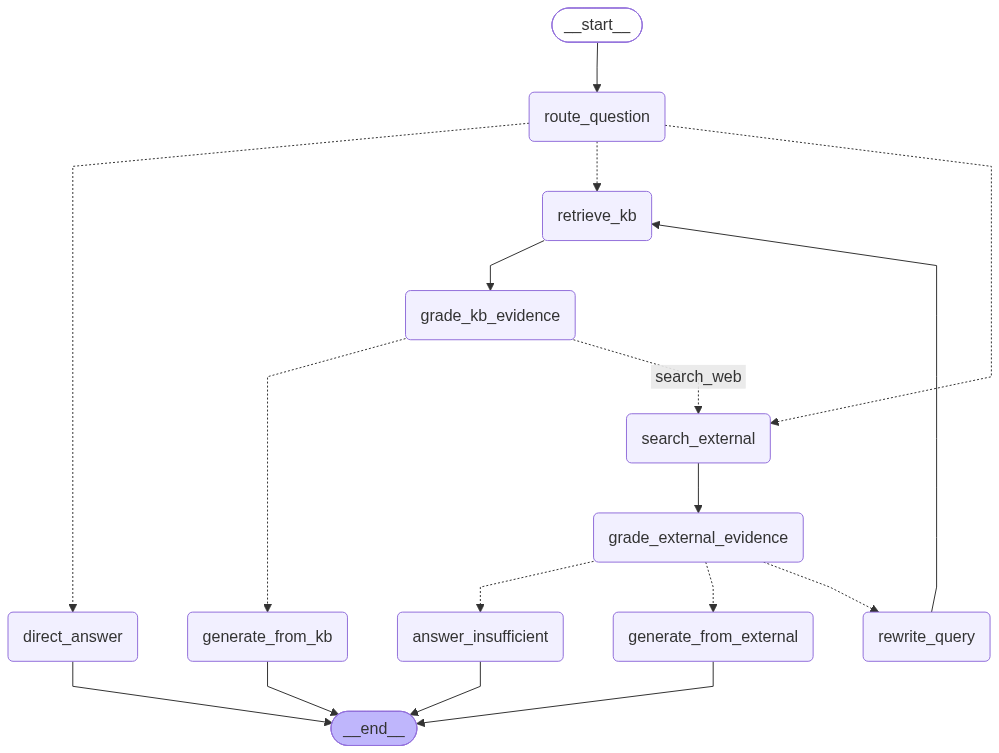

In [81]:
from IPython.display import Image, display

try:
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception as e:
    print("Graph visualization is optional. The graph can still run.")
    print("Reason:", e)

In [82]:
def ask_agent(question: str):
    initial_state: AgentState = {
        "question": question,
        "current_query": question,
        "kb_docs": [],
        "external_results": "",
        "tools_used": [],
        "kb_grade": "",
        "external_grade": "",
        "answer": "",
        "source_used": "",
        "retry_count": 0,
    }

    result = app.invoke(initial_state)

    print("\n" + "=" * 90)
    print("QUESTION:")
    print(question)
    print("\nSOURCE USED:")
    print(result["source_used"])
    if result.get("tools_used"):
        print("\nEXTERNAL TOOLS USED:")
        print(", ".join(result["tools_used"]))
    print("\nFINAL ANSWER:")
    print(result["answer"])
    print("=" * 90)

    return result

In [64]:
result = ask_agent("What is the Origin of the virus?")

[Router] kb
[KB Retriever] Query: What is the Origin of the virus?
[KB Retriever] Retrieved: 4 chunks
[KB Grader] good

QUESTION:
What is the Origin of the virus?

SOURCE USED:
private_kb

FINAL ANSWER:
**Answer (based on the private KB)**  
The virus most likely originated from a spillover event where it jumped from an intermediary animal host into humans. Environmental samples from the Wuhan market were positive for the virus, especially in areas where wild and farmed animals were traded, suggesting the market could have been the origin or an amplifying setting for the initial spread.  

*Source type: Private KB*


In [83]:
result = ask_agent("What is the latest COVID-19 variant of concern according to the WHO?")

[Router] kb
[KB Retriever] Query: What is the latest COVID-19 variant of concern according to the WHO?
[KB Retriever] Retrieved: 4 chunks
[KB Grader] weak
[External Tools] Calling: tavily_search | args: {'query': 'latest COVID-19 variant of concern WHO', 'search_depth': 'basic', 'topic': 'news'}
[External Tools] Tools used: ['tavily_search']
[External Tools] Result characters: 6759
[External Grader] good

QUESTION:
What is the latest COVID-19 variant of concern according to the WHO?

SOURCE USED:
external_tools

EXTERNAL TOOLS USED:
tavily_search

FINAL ANSWER:
**Answer**

According to the World Health Organization (WHO), the most recent COVID‑19 variant that has been classified as a *Variant of Concern* (VOC) is **Omicron** (scientific name B.1.1.529).  

- Omicron was first identified in November 2021 and has since become the dominant strain worldwide.  
- It spreads more easily than earlier strains (such as the original virus and Delta) but tends to cause less severe disease in many

In [84]:
result = ask_agent("what is 1706.03762")

[Router] external (arXiv ID detected)
[External Tools] Calling: arxiv | args: {'query': '1706.03762'}
[External Tools] arXiv returned nothing useful -> Tool error: 'Search' object has no attribute 'results'
[External Tools] Calling: tavily_search | args: {'query': 'what is 1706.03762'}
[External Tools] arxiv returned little/nothing: Tool error: 'Search' object has no attribute 'results'
[External Tools] Tools used: ['arxiv', 'tavily_search']
[External Tools] Result characters: 6721
[External Grader] good

QUESTION:
what is 1706.03762

SOURCE USED:
external_tools

EXTERNAL TOOLS USED:
arxiv, tavily_search

FINAL ANSWER:
**1706.03762** is the arXiv identifier for a research paper titled **“Attention Is All You Need.”**  
The paper was written by Ashish Vaswani, Noam Shazeer, Niki Parmar, Jakob Uszkoreit, Llion Jones, Aidan N. Gomez, Łukasz Kaiser, and Illia Polosukhin and was published in 2017.

### What the paper is about
- It introduces the **Transformer** architecture, a neural‑networ

In [85]:
result = ask_agent("Find recent research papers about retrieval-augmented generation for LLMs.")

[Router] external
[External Tools] Calling: arxiv | args: {'query': 'retrieval-augmented generation LLMs'}
[External Tools] arXiv returned nothing useful -> Tool error: 'Search' object has no attribute 'results'
[External Tools] Calling: tavily_search | args: {'query': 'Find recent research papers about retrieval-augmented generation for LLMs.'}
[External Tools] arxiv returned little/nothing: Tool error: 'Search' object has no attribute 'results'
[External Tools] Tools used: ['arxiv', 'tavily_search']
[External Tools] Result characters: 7468
[External Grader] good

QUESTION:
Find recent research papers about retrieval-augmented generation for LLMs.

SOURCE USED:
external_tools

EXTERNAL TOOLS USED:
arxiv, tavily_search

FINAL ANSWER:
**Recent research papers on Retrieval‑Augmented Generation (RAG) for large language models (LLMs)**  

| Year | Paper title | Authors | Key idea for beginners | Where to read it |
|------|-------------|---------|------------------------|------------------|

In [48]:
result = ask_agent("What is Tavily Search and why is it useful for AI agents and RAG workflows?")

[Router] direct

QUESTION:
What is Tavily Search and why is it useful for AI agents and RAG workflows?

SOURCE USED:
direct

FINAL ANSWER:
Tavily Search is a web‑search API that pulls fresh, curated results (and sometimes structured data) from the internet.  
For AI agents it gives a quick, reliable way to fetch up‑to‑date facts or verify claims.  
In RAG (Retrieval‑Augmented Generation) workflows it supplies the “retrieval” step—providing relevant documents or snippets that the language model can cite, which cuts hallucinations and keeps answers grounded in real‑world data.


In [86]:
result = ask_agent("What do recent research papers and current news say about long COVID treatments?")

[Router] external
[External Tools] Calling: arxiv | args: {'query': 'long COVID treatments'}
[External Tools] Calling: tavily_search | args: {'query': 'What do recent research papers and current news say about long COVID treatments?'}
[External Tools] arxiv returned little/nothing: Tool error: 'Search' object has no attribute 'results'
[External Tools] Tools used: ['arxiv', 'tavily_search']
[External Tools] Result characters: 8093
[External Grader] good

QUESTION:
What do recent research papers and current news say about long COVID treatments?

SOURCE USED:
external_tools

EXTERNAL TOOLS USED:
arxiv, tavily_search

FINAL ANSWER:
**What the latest papers and news reports say about treating long COVID**

| What researchers and journalists are saying | Key points | Source |
|---------------------------------------------|------------|--------|
| **No single “cure” yet** | Long COVID is still a complex, multi‑system condition.  Current care focuses on relieving symptoms (pain, fatigue, brea